# MAP estimation on a smoothed patient fiber field

Minimal run and analysis. The ground truth is the fiber field of patient 01 smoothed with a Gaussian of scale 3 (`patient_data/patient_01/smoothed_scale_3/angle_field.npy`, made by `scripts/smooth_patient_fibers.py`); the activation times are *synthetic*, forward-solved from that field and sampled sparsely with noise, as no measured activation times are available. The prior mean is zero and the optimization starts there.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
from ls_bayesian.common.logging import BaseLogger, LoggerSettings

from bayes_cep.mesh.geodesic import assemble_edge_length_graph, compute_graph_distances
from bayes_cep.mesh.interpolation import NearestNeighborInterpolationStrategy
from bayes_cep.mesh.io import load_pyvista_mesh
from bayes_cep.posterior.builder import PosteriorBuilder, PosteriorSettings
from bayes_cep.posterior.eikonal_map import EikonalParameterToSolutionMap
from bayes_cep.posterior.likelihood import LikelihoodSettings
from bayes_cep.posterior.prior import PriorParameters
from bayes_cep.preprocessing.synthetic_observations import (
    ObservationSamplingSettings,
    generate_synthetic_observations,
)
from bayes_cep.statistics.axial_error_metrics import (
    compute_axial_error_metrics,
    compute_error_by_distance,
    compute_skill_score,
)
from bayes_cep.statistics.axial_statistics import (
    compute_axial_data_diff,
    shift_angles_to_minimize_axial_variance,
    wrap_axial_angles,
)
from single_runs.reference import (
    NOISE_VARIANCE,
    NUM_OBSERVATIONS,
    OBSERVATION_SEED,
    reference_eikonal_settings,
    reference_optimizer_strategy,
)

pv.set_jupyter_backend("trame")

## Settings

The patient directory holds `mesh.vtu`, `basis_vecs.npy` and `fiber_field.npy`. Prior parameters, number of observations and noise default to the reference values; the eikonal settings (initial site, velocities) are those of patient 01, so change them for another patient.

In [3]:
PATIENT_DIR = Path.cwd().parent / "example_data" / "raw"
SMOOTHED_ANGLES_PATH = (
    PATIENT_DIR.parent.parent / "patient_data" / "patient_01" / "smoothed_scale_3" / "angle_field.npy"
)
# The best pair of the simulated-moment fit of the smoothed field of patient 01
# (`notebooks/prior_estimation.ipynb`, loss 0.023); the pair that fits the other six patients best
# is the same, so it also holds out of sample. kappa * tau is 0.28. Smoother pairs along the valley,
# (0.1, 2.0) and (0.1, 3.0), fit about as well; (0.3, 1.4) is rougher and fitted the field of the
# earlier MAP runs slightly better.
PRIOR = PriorParameters(kappa=0.2, tau=1.4, seed=0)
# Initial guess of the optimization: a constant angle [rad]. None takes the constant that fits the
# observations best (scanned below). It is not prior information (the prior mean stays zero): it only
# puts the seam of the branch window (-pi/2, pi/2] around the angles of the field, away from the
# optimizer's starting point, where regions on both sides of it settle on different branches.
INITIAL_CONSTANT = None
OBSERVATIONS = ObservationSamplingSettings(
    num_observations=NUM_OBSERVATIONS, noise_variance=NOISE_VARIANCE, seed=OBSERVATION_SEED
)
MAX_NUM_ITERATIONS = None  # None: the reference value (1000); set lower for a quick test

## Data: patient ground truth and synthetic observations

In [4]:
mesh = load_pyvista_mesh(PATIENT_DIR / "mesh.vtu")
basis_vectors = np.load(PATIENT_DIR / "basis_vecs.npy")
eikonal_settings = reference_eikonal_settings()
interpolation_strategy = NearestNeighborInterpolationStrategy()
connectivity = mesh.cells.reshape(-1, 4)[:, 1:]
vertex_to_simplex_matrix = interpolation_strategy.assemble_matrix(mesh.points, connectivity)

# The prior is real-valued, so the smoothed angles are shifted by multiples of pi into one window
ground_truth = shift_angles_to_minimize_axial_variance(np.load(SMOOTHED_ANGLES_PATH))
prior_mean = np.zeros_like(ground_truth)
forward_map = EikonalParameterToSolutionMap(
    mesh, basis_vectors, eikonal_settings, interpolation_strategy
)
observed_vertex_indices, observed_activation_times = generate_synthetic_observations(
    forward_map, ground_truth, OBSERVATIONS
)
print(f"{mesh.n_points} vertices, {mesh.n_cells} triangles, {observed_vertex_indices.size} observed")

15820 vertices, 31375 triangles, 1000 observed


## Posterior and MAP estimate

The prior mean is zero. The optimization starts at a constant angle: the one that minimizes the likelihood cost over a scan of constants (or `INITIAL_CONSTANT`).

In [6]:
log_posterior = PosteriorBuilder(
    PosteriorSettings(
        mesh=mesh,
        basis_vectors=basis_vectors,
        prior_mean_vector=prior_mean,
        prior_parameters=PRIOR,
        eikonal_settings=eikonal_settings,
        likelihood_settings=LikelihoodSettings(
            num_vertices=mesh.points.shape[0],
            observed_vertex_indices=observed_vertex_indices,
            data_vector=observed_activation_times,
            noise_variance=OBSERVATIONS.noise_variance,
        ),
    ),
    interpolation_strategy=interpolation_strategy,
).build()

if INITIAL_CONSTANT is None:
    candidates = np.linspace(-np.pi / 2, np.pi / 2, 25, endpoint=False)
    scanned_costs = [
        log_posterior.evaluate_likelihood_cost(np.full(mesh.n_points, constant))
        for constant in candidates
    ]
    initial_constant = float(candidates[np.argmin(scanned_costs)])
else:
    initial_constant = INITIAL_CONSTANT
initial_guess = np.full(mesh.n_points, initial_constant)
print(f"initial guess: constant {initial_constant:.2f} rad")

strategy = reference_optimizer_strategy()
if MAX_NUM_ITERATIONS is not None:
    strategy.lbfgs_settings.maximum_num_iterations = MAX_NUM_ITERATIONS
with BaseLogger(LoggerSettings(), prefix="map") as logger:
    model, optimizer = strategy.build(log_posterior, logger)
    result = optimizer.run(initial_guess=initial_guess, model=model)
map_estimate = result.result
print(f"success: {result.success}\nstatus: {result.status_message}")

fig, (loss_axis, gradient_axis) = plt.subplots(1, 2, figsize=(10, 4))
loss_axis.semilogy(result.loss_history)
loss_axis.set_xlabel("iteration")
loss_axis.set_ylabel("loss")
gradient_axis.semilogy(result.gradient_norm_history)
gradient_axis.set_xlabel("iteration")
gradient_axis.set_ylabel("gradient norm")
fig.tight_layout()

KeyboardInterrupt: 

## Estimate vs. ground truth

Compared on simplices, as the forward model sees the field. The error is axial, so a shift by $\pi$ is no error.

In [7]:
truth_simplex = vertex_to_simplex_matrix @ ground_truth
estimate_simplex = vertex_to_simplex_matrix @ map_estimate
prior_mean_simplex = vertex_to_simplex_matrix @ prior_mean
error = compute_axial_data_diff(estimate_simplex, truth_simplex)
prior_mean_error = compute_axial_data_diff(prior_mean_simplex, truth_simplex)

# The parameter is a real number, but the fiber is axial: plot the angle modulo pi
clim = (-np.pi / 2, np.pi / 2)
for name, values, cmap, limits in (
    ("ground truth (smoothed patient)", wrap_axial_angles(truth_simplex), "hsv", clim),
    ("MAP estimate", wrap_axial_angles(estimate_simplex), "hsv", clim),
    ("absolute axial error [deg]", np.degrees(np.abs(error)), "viridis", (0.0, 90.0)),
):
    plot_mesh = mesh.copy()
    plot_mesh.cell_data["value"] = values
    plotter = pv.Plotter()
    plotter.add_mesh(plot_mesh, scalars="value", cmap=cmap, clim=limits)
    plotter.add_text(name)
    plotter.show()

Widget(value='<iframe src="http://localhost:40033/index.html?ui=P_0x7f078d65a270_0&reconnect=auto" class="pyvi…

Widget(value='<iframe src="http://localhost:40033/index.html?ui=P_0x7f0660949310_1&reconnect=auto" class="pyvi…

Widget(value='<iframe src="http://localhost:40033/index.html?ui=P_0x7f066051c550_2&reconnect=auto" class="pyvi…

## Error metrics

In [8]:
metrics = compute_axial_error_metrics(error)
prior_mean_metrics = compute_axial_error_metrics(prior_mean_error)
metrics["skill_score"] = compute_skill_score(
    metrics["error_mean_deg"], prior_mean_metrics["error_mean_deg"]
)
print(f"{'metric':<24}{'prior mean':>12}{'MAP':>12}")
for key, value in metrics.items():
    print(f"{key:<24}{prior_mean_metrics.get(key, float('nan')):>12.4g}{value:>12.4g}")

true_times = forward_map.evaluate_forward(ground_truth)
estimate_times = forward_map.evaluate_forward(map_estimate)
is_observed = np.zeros(mesh.n_points, dtype=bool)
is_observed[observed_vertex_indices] = True
for name, selection in (("all", ~is_observed | is_observed), ("observed", is_observed), ("unobserved", ~is_observed)):
    rmse = np.sqrt(np.mean((estimate_times - true_times)[selection] ** 2))
    print(f"activation-time RMSE, {name:<10}: {rmse:.4f}")

metric                    prior mean         MAP
error_mean_deg                  48.9       14.86
error_median_deg               51.33       6.762
error_p90_deg                   83.1       42.44
error_p95_deg                   86.5       57.42
error_p99_deg                  89.36       81.01
error_max_deg                     90       89.98
fraction_below_5_deg         0.03312      0.4103
fraction_below_10_deg         0.0843      0.6024
fraction_below_20_deg         0.1747      0.7564
axial_concentration          -0.1027      0.7542
skill_score                      nan      0.6961
activation-time RMSE, all       : 0.0782
activation-time RMSE, observed  : 0.0342
activation-time RMSE, unobserved: 0.0803


## Error distribution and error vs. distance to the observations

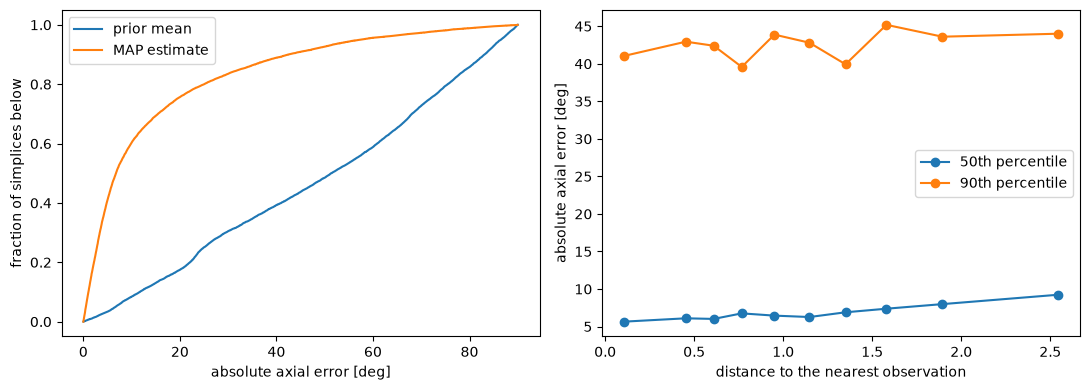

In [9]:
absolute_error_deg = np.degrees(np.abs(error))
vertex_distances = compute_graph_distances(
    assemble_edge_length_graph(mesh.points, connectivity), observed_vertex_indices, min_over_sources=True
)
quantiles = (0.5, 0.9)
bin_distances, bin_errors = compute_error_by_distance(
    vertex_to_simplex_matrix @ vertex_distances, absolute_error_deg, num_bins=10, quantiles=quantiles
)

fig, (cdf_axis, distance_axis) = plt.subplots(1, 2, figsize=(11, 4))
for name, values in (("prior mean", np.degrees(np.abs(prior_mean_error))), ("MAP estimate", absolute_error_deg)):
    sorted_values = np.sort(values)
    cdf_axis.plot(sorted_values, np.arange(1, sorted_values.size + 1) / sorted_values.size, label=name)
cdf_axis.set_xlabel("absolute axial error [deg]")
cdf_axis.set_ylabel("fraction of simplices below")
cdf_axis.legend()
for quantile, values in zip(quantiles, bin_errors.T, strict=True):
    distance_axis.plot(bin_distances, values, marker="o", label=f"{int(100 * quantile)}th percentile")
distance_axis.set_xlabel("distance to the nearest observation")
distance_axis.set_ylabel("absolute axial error [deg]")
distance_axis.legend()
fig.tight_layout()

## Loss at the MAP estimate vs. at the smoothed field

The smoothed field is not a sample of the prior, so its prior cost is above $N/2$. A lower loss at the smoothed field than at the MAP estimate would mean the optimizer stopped early.

In [10]:
for name, field in (("MAP estimate", map_estimate), ("smoothed field", ground_truth)):
    likelihood_cost = log_posterior.evaluate_likelihood_cost(field)
    prior_cost = log_posterior.evaluate_prior_cost(field)
    print(f"{name:<14} loss {likelihood_cost + prior_cost:>12.1f}  (likelihood {likelihood_cost:>10.1f}, prior {prior_cost:>10.1f})")

MAP estimate   loss        952.8  (likelihood      441.2, prior      511.6)
smoothed field loss     120335.5  (likelihood      477.6, prior   119857.9)


## Smoothing the MAP estimate

The MAP estimate has steep transitions (strips where the angle changes by tens of degrees within a few elements) that are neither in the prior nor, mostly, in the truth. They are real steep gradients, not branch mismatches (the estimate is already on one branch), so relabeling by multiples of $\pi$ does not remove them.

`smooth_axial_angle_field` smooths the doubled-angle vector with the heat equation, which also blurs the broad structure. `smooth_axial_angle_field_adaptive` makes the diffusivity grow with the gradient, $1 + (|\nabla z|/g_0)^2$, so that narrow steep strips are removed quickly and smooth regions change little. $g_0$ is a quantile of the gradients of the estimate itself (`GRADIENT_QUANTILE`; smaller removes more). At the same number of steep edges, the adaptive smoothing changes the regions away from the steep strips by about 1 to 1.5 degrees less than the linear one (the column `change*` of the table; on the stored example 379 steep edges with a change of 5.8 degrees, against 425 and 6.2 for the linear smoothing with scale 2). The gain is modest, and the error against the truth is the same. The coherence of the smoothed estimate is low where fibers rotate quickly, so the angle there is not meaningful. `smooth_axial_angle_field_median` is a vector median filter on the doubled-angle vectors (every vertex takes the member of its neighborhood closest to all others, then a light linear smoothing): it removes structures narrower than about half the neighborhood, such as strips and small rings, and keeps broad transitions. On the stored example it left the fewest steep edges per change of the smooth regions (see the table). An optional `confidence` weight per vertex (for example a posterior-based one) is smoothed along with the field.

In [11]:
from bayes_cep.mesh.topology import get_triangle_connectivity
from bayes_cep.statistics.axial_smoothing import (
    estimate_gradient_scale,
    smooth_axial_angle_field,
    smooth_axial_angle_field_adaptive,
    smooth_axial_angle_field_median,
)

POST_SMOOTHING_SCALE = 1.5  # in mesh units; the truth is smoothed with 3
GRADIENT_QUANTILE = 0.8  # gradients above this quantile of the estimate count as steep
LINEAR_COMPARISON_SCALE = 2.0  # linear smoothing with a similar number of steep edges left
MEDIAN_RINGS = 3  # neighborhood of the vector median filter, in edges
MEDIAN_ITERATIONS = 2
MEDIAN_LINEAR_SCALE = 1.0  # light linear smoothing after the median filter
gradient_scale = estimate_gradient_scale(mesh, map_estimate, GRADIENT_QUANTILE)
smoothed_estimate, estimate_coherence = smooth_axial_angle_field_adaptive(
    mesh, map_estimate, POST_SMOOTHING_SCALE, gradient_scale
)
linear_estimate, _ = smooth_axial_angle_field(mesh, map_estimate, LINEAR_COMPARISON_SCALE)
median_estimate, median_coherence = smooth_axial_angle_field_median(
    mesh, map_estimate, MEDIAN_RINGS, MEDIAN_ITERATIONS, MEDIAN_LINEAR_SCALE
)

triangles = get_triangle_connectivity(mesh)
edges = np.unique(
    np.sort(np.concatenate([triangles[:, [0, 1]], triangles[:, [1, 2]], triangles[:, [2, 0]]]), axis=1),
    axis=0,
)


def edge_jumps(angles):
    return np.degrees(np.abs(wrap_axial_angles(angles[edges[:, 0]] - angles[edges[:, 1]])))


def steep_edges(angles, threshold_degrees=20.0):
    return int(np.sum(edge_jumps(angles) > threshold_degrees))


# Vertices away from the steep strips of the estimate: how much a smoothing changes the field there
steep_vertices = np.unique(edges[edge_jumps(map_estimate) > 20.0])
is_smooth_region = np.ones(mesh.n_points, dtype=bool)
is_smooth_region[steep_vertices] = False


print(f"{'':<26}{'mean error':>11}{'median':>9}{'p90':>8}{'< 10 deg':>10}{'steep edges':>13}{'change*':>8}")
for name, field in (
    ("truth", ground_truth),
    ("MAP estimate", map_estimate),
    (f"linear smoothing {LINEAR_COMPARISON_SCALE:g}", linear_estimate),
    (f"adaptive smoothing {POST_SMOOTHING_SCALE:g}", smoothed_estimate),
    (f"median {MEDIAN_RINGS} rings, {MEDIAN_ITERATIONS}x + linear {MEDIAN_LINEAR_SCALE:g}", median_estimate),
):
    field_error = np.degrees(
        np.abs(compute_axial_data_diff(vertex_to_simplex_matrix @ field, truth_simplex))
    )
    change = np.degrees(np.abs(wrap_axial_angles(field - map_estimate)))[is_smooth_region].mean()
    print(
        f"{name:<26}{field_error.mean():>10.1f}d{np.median(field_error):>8.1f}d"
        f"{np.quantile(field_error, 0.9):>7.1f}d{np.mean(field_error < 10):>10.2f}"
        f"{steep_edges(field):>13}{change:>7.1f}d"
    )
print("* mean change of the angle against the MAP estimate, at the vertices without a steep edge of it")

for name, values, cmap, limits in (
    ("MAP estimate, adaptively smoothed", wrap_axial_angles(vertex_to_simplex_matrix @ smoothed_estimate), "hsv", (-np.pi / 2, np.pi / 2)),
    ("MAP estimate, median filter", wrap_axial_angles(vertex_to_simplex_matrix @ median_estimate), "hsv", (-np.pi / 2, np.pi / 2)),
    ("coherence of the smoothed estimate", vertex_to_simplex_matrix @ estimate_coherence, "viridis", (0.0, 1.0)),
):
    plot_mesh = mesh.copy()
    plot_mesh.cell_data["value"] = values
    plotter = pv.Plotter()
    plotter.add_mesh(plot_mesh, scalars="value", cmap=cmap, clim=limits)
    plotter.add_text(name)
    plotter.show()

                           mean error   median     p90  < 10 deg  steep edges change*
truth                            0.0d     0.0d    0.0d      1.00          405   12.9d
MAP estimate                    14.9d     6.8d   42.4d      0.60         1596    0.0d
linear smoothing 2              12.9d     6.8d   33.5d      0.61          303    6.0d
adaptive smoothing 1.5          12.9d     6.6d   34.2d      0.61          275    5.6d
median 3 rings, 2x + linear 1      12.7d     6.0d   33.9d      0.63          312    4.8d
* mean change of the angle against the MAP estimate, at the vertices without a steep edge of it


Widget(value='<iframe src="http://localhost:40033/index.html?ui=P_0x7f061bf28550_3&reconnect=auto" class="pyvi…

Widget(value='<iframe src="http://localhost:40033/index.html?ui=P_0x7f061bfc9590_4&reconnect=auto" class="pyvi…

Widget(value='<iframe src="http://localhost:40033/index.html?ui=P_0x7f061bfcb250_5&reconnect=auto" class="pyvi…